# Análisis de Multicolinealidad y Sensibilidad de nGAIN

Análisis de robustez solicitado por revisores (camera-ready):

1. **Matriz de correlaciones de Spearman** entre PD, AMB, nGAIN, CONS, LEC y PROX (n=360 pistas)
2. **VIF** (Variance Inflation Factor) de las cinco métricas incluidas en las regresiones: PD, AMB, nGAIN, CONS y LEC
3. **Sensibilidad de nGAIN** respecto a distintos valores de la temperatura τ: 0.01, 0.03, 0.05, 0.1, 0.2, 0.5, 1.0

> El valor τ=0.05 es el utilizado en el paper.
> PROX = similitud coseno directa entre el embedding de la pista y el embedding del nombre del personaje objetivo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from scipy.stats import spearmanr
from scipy.special import softmax
from scipy.stats import entropy
from sklearn.metrics.pairwise import cosine_similarity
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from sentence_transformers import SentenceTransformer

plt.rcParams['figure.figsize'] = (10, 7)
plt.rcParams['font.size'] = 11

FOTOS_DIR = Path('fotos')
FOTOS_DIR.mkdir(exist_ok=True)

print('Librerías cargadas correctamente')

C:\Users\Alonso\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Librerías cargadas correctamente


## 1. Carga de datos y cómputo de PROX

In [2]:
# Cargar CSV con métricas precalculadas
df = pd.read_csv(Path('../results/df_pistas_with_semantic_features.csv'))
print(f'Pistas cargadas: {len(df)}')
print(f'Personajes únicos: {df["nombre"].nunique()}')
print(df[['PD', 'AMB', 'nGAIN', 'CONS', 'LEC', 'CLAMP']].describe().round(4))

Pistas cargadas: 360
Personajes únicos: 45
             PD       AMB     nGAIN      CONS       LEC     CLAMP
count  360.0000  360.0000  360.0000  360.0000  360.0000  360.0000
mean     0.1252    0.6003    0.4088    0.7534    0.9513    0.8434
std      0.1356    0.1579    0.2045    0.0423    0.0966    0.1342
min     -0.2574    0.3285    0.0757    0.5734    0.2928    0.3443
25%      0.0328    0.5026    0.2518    0.7325    0.9530    0.7895
50%      0.1082    0.5723    0.3617    0.7557    0.9845    0.8925
75%      0.2130    0.6592    0.5249    0.7822    0.9948    0.9339
max      0.5288    1.9099    0.9565    0.8828    0.9999    0.9878


In [3]:
# Parsear embeddings almacenados como strings de numpy
def parse_embedding(s):
    return np.array([float(x) for x in s.strip('[]').replace('\n', ' ').split()])

print('Parseando embeddings de pistas...')
hint_embs = np.stack(df['hint_embedding'].apply(parse_embedding).values)
print(f'Matriz de embeddings: {hint_embs.shape}')

Parseando embeddings de pistas...
Matriz de embeddings: (360, 384)


In [4]:
# Cargar modelo y calcular embeddings de nombres de personajes
# (misma configuración que el notebook original propuesta_calidad_pistas.ipynb)
print('Cargando modelo sentence-transformers...')
model = SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')

characters = df['nombre'].unique().tolist()
print(f'Calculando embeddings de {len(characters)} personajes...')
char_embeddings = model.encode(characters, show_progress_bar=False)
char_emb_dict = {char: emb for char, emb in zip(characters, char_embeddings)}

# PROX = cosine_similarity(hint_emb, target_emb)
target_embs = np.stack([char_emb_dict[n] for n in df['nombre'].values])
prox_values = np.array([
    float(cosine_similarity(hint_embs[i:i+1], target_embs[i:i+1])[0, 0])
    for i in range(len(df))
])
df['PROX'] = prox_values

print(f'\nPROX: μ = {prox_values.mean():.4f},  σ = {prox_values.std():.4f}')
print(f'Rango PROX: [{prox_values.min():.4f}, {prox_values.max():.4f}]')

Cargando modelo sentence-transformers...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   1%|          | 1/199 [00:00<?, ?it/s, Materializing param=embeddings.LayerNorm.bias]

Loading weights:   1%|          | 1/199 [00:00<00:01, 146.08it/s, Materializing param=embeddings.LayerNorm.bias]

Loading weights:   1%|          | 2/199 [00:00<00:00, 271.85it/s, Materializing param=embeddings.LayerNorm.weight]

...

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 352.94it/s, Materializing param=pooler.dense.weight]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 328.78it/s, Materializing param=pooler.dense.weight]


BertModel LOAD REPORT from: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Calculando embeddings de 45 personajes...



PROX: μ = 0.2730,  σ = 0.1529
Rango PROX: [-0.0941, 0.6778]


## 2. Matriz de correlaciones de Spearman

In [5]:
METRICS = ['PD', 'AMB', 'nGAIN', 'CONS', 'LEC', 'PROX']
data_metrics = df[METRICS]

# Spearman con p-valores
rho, pvals = spearmanr(data_metrics)
rho_df  = pd.DataFrame(rho,   index=METRICS, columns=METRICS)
pval_df = pd.DataFrame(pvals, index=METRICS, columns=METRICS)

print('Matriz de correlaciones de Spearman (ρ):')
print(rho_df.round(3).to_string())
print('\nP-valores:')
print(pval_df.round(4).to_string())

Matriz de correlaciones de Spearman (ρ):
          PD    AMB  nGAIN   CONS    LEC   PROX
PD     1.000 -0.921  0.529  0.043 -0.129  0.872
AMB   -0.921  1.000 -0.313 -0.061  0.076 -0.868
nGAIN  0.529 -0.313  1.000  0.105 -0.083  0.533
CONS   0.043 -0.061  0.105  1.000  0.041  0.162
LEC   -0.129  0.076 -0.083  0.041  1.000 -0.053
PROX   0.872 -0.868  0.533  0.162 -0.053  1.000

P-valores:
           PD     AMB   nGAIN    CONS     LEC    PROX
PD     0.0000  0.0000  0.0000  0.4141  0.0144  0.0000
AMB    0.0000  0.0000  0.0000  0.2464  0.1485  0.0000
nGAIN  0.0000  0.0000  0.0000  0.0467  0.1164  0.0000
CONS   0.4141  0.2464  0.0467  0.0000  0.4358  0.0020
LEC    0.0144  0.1485  0.1164  0.4358  0.0000  0.3178
PROX   0.0000  0.0000  0.0000  0.0020  0.3178  0.0000


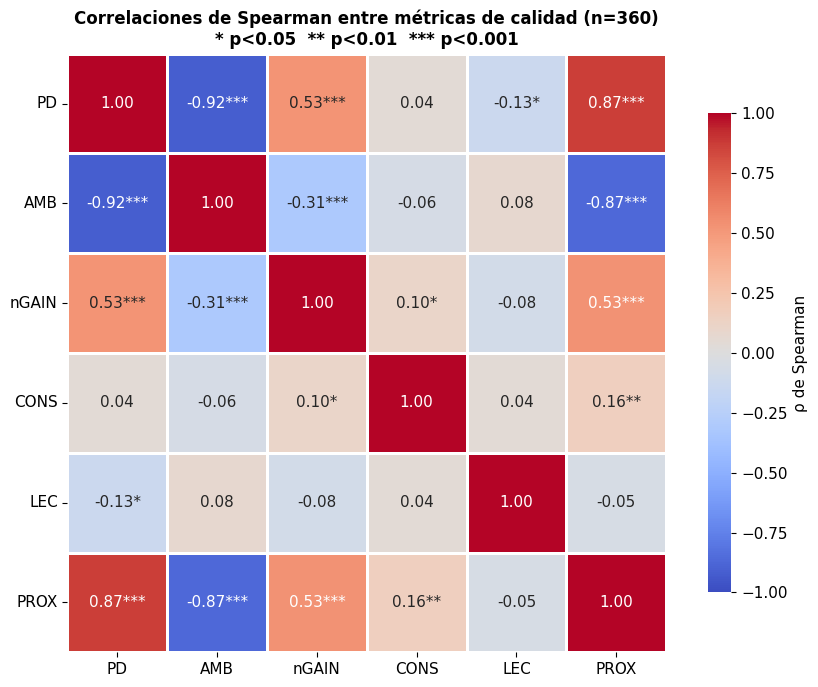

Figura guardada: fotos/spearman_correlation.png


In [6]:
# Función para añadir asteriscos de significatividad
def sig_stars(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return ''

n = len(METRICS)
annot = np.full((n, n), '', dtype=object)
for i in range(n):
    for j in range(n):
        if i == j:
            annot[i, j] = '1.00'
        else:
            stars = sig_stars(pval_df.iloc[i, j])
            annot[i, j] = f'{rho_df.iloc[i, j]:.2f}{stars}'

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    rho_df, annot=annot, fmt='', cmap='coolwarm', center=0,
    vmin=-1, vmax=1, square=True, linewidths=0.8,
    cbar_kws={'shrink': 0.8, 'label': 'ρ de Spearman'},
    ax=ax
)
ax.set_title('Correlaciones de Spearman entre métricas de calidad (n=360)\n'
             '* p<0.05  ** p<0.01  *** p<0.001',
             fontweight='bold', fontsize=12)
ax.tick_params(axis='x', rotation=0)
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.savefig(FOTOS_DIR / 'spearman_correlation.png', dpi=300, bbox_inches='tight')
plt.show()
print('Figura guardada: fotos/spearman_correlation.png')

## 3. VIF de las métricas de regresión (PD, AMB, nGAIN, CONS, LEC)

In [7]:
REG_METRICS = ['PD', 'AMB', 'nGAIN', 'CONS', 'LEC']
X = df[REG_METRICS].copy()
X_const = add_constant(X)  # añadir intercepto para el cálculo de VIF

vif_values = [
    variance_inflation_factor(X_const.values, i + 1)  # +1 por la constante
    for i in range(len(REG_METRICS))
]

vif_df = pd.DataFrame({
    'Métrica': REG_METRICS,
    'VIF': vif_values
})
vif_df['Diagnóstico'] = vif_df['VIF'].apply(
    lambda v: 'OK (< 5)' if v < 5 else ('Moderado (5-10)' if v < 10 else 'Severo (> 10)')
)

print('VIF de las métricas incluidas en las regresiones:')
print(vif_df.to_string(index=False))
print('\nUmbral habitual: VIF < 5 = sin multicolinealidad problemática')

VIF de las métricas incluidas en las regresiones:
Métrica      VIF     Diagnóstico
     PD 5.177676 Moderado (5-10)
    AMB 3.449620        OK (< 5)
  nGAIN 2.065730        OK (< 5)
   CONS 1.012344        OK (< 5)
    LEC 1.003933        OK (< 5)

Umbral habitual: VIF < 5 = sin multicolinealidad problemática


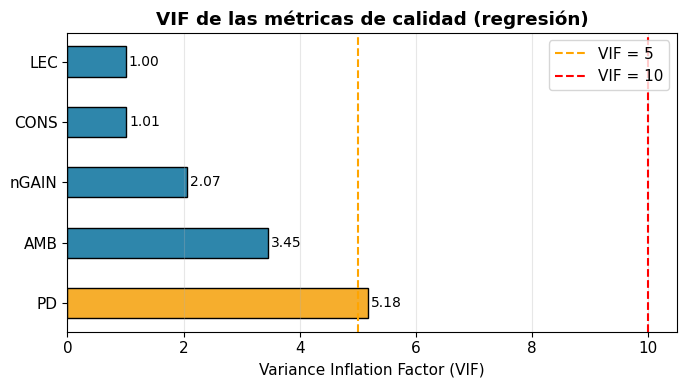

Figura guardada: fotos/vif_metrics.png


In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
colors = ['#2E86AB' if v < 5 else ('#F6AE2D' if v < 10 else '#F26419')
          for v in vif_df['VIF']]
bars = ax.barh(vif_df['Métrica'], vif_df['VIF'], color=colors, edgecolor='black', height=0.5)
ax.axvline(5,  color='orange', linestyle='--', linewidth=1.5, label='VIF = 5')
ax.axvline(10, color='red',    linestyle='--', linewidth=1.5, label='VIF = 10')
for bar, val in zip(bars, vif_df['VIF']):
    ax.text(val + 0.05, bar.get_y() + bar.get_height()/2,
            f'{val:.2f}', va='center', fontsize=10)
ax.set_xlabel('Variance Inflation Factor (VIF)')
ax.set_title('VIF de las métricas de calidad (regresión)', fontweight='bold')
ax.legend()
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(FOTOS_DIR / 'vif_metrics.png', dpi=300, bbox_inches='tight')
plt.show()
print('Figura guardada: fotos/vif_metrics.png')

## 4. Sensibilidad de nGAIN para distintos valores de τ

In [9]:
# Todos los embeddings de personajes (uno por personaje único)
char_names_list = df['nombre'].unique().tolist()
all_char_embs = np.stack([char_emb_dict[c] for c in char_names_list])
N_candidates = len(char_names_list)
H0 = np.log(N_candidates)  # entropía máxima

print(f'Candidatos (personajes): {N_candidates}')
print(f'Entropía máxima H₀ = log({N_candidates}) = {H0:.4f}')

def compute_ngain_tau(hint_emb, all_embs, tau):
    """nGAIN = (H0 - H) / H0  con softmax a temperatura τ."""
    sims = cosine_similarity(hint_emb.reshape(1, -1), all_embs)[0]
    probs = softmax(sims / tau)
    H = entropy(probs)
    return (H0 - H) / H0 if H0 > 0 else 0.0

TAU_VALUES = [0.01, 0.03, 0.05, 0.1, 0.2, 0.5, 1.0]
TAU_PAPER  = 0.05

print(f'\nComputando nGAIN para τ ∈ {TAU_VALUES}...')
ngain_per_tau = {}
for tau in TAU_VALUES:
    vals = [
        compute_ngain_tau(hint_embs[i], all_char_embs, tau)
        for i in range(len(df))
    ]
    ngain_per_tau[tau] = np.array(vals)
    print(f'  τ={tau:.2f}  →  μ={np.mean(vals):.4f},  σ={np.std(vals):.4f}')

print('Hecho.')

Candidatos (personajes): 45
Entropía máxima H₀ = log(45) = 3.8067

Computando nGAIN para τ ∈ [0.01, 0.03, 0.05, 0.1, 0.2, 0.5, 1.0]...


  τ=0.01  →  μ=0.9009,  σ=0.1114


  τ=0.03  →  μ=0.6386,  σ=0.2033


  τ=0.05  →  μ=0.4088,  σ=0.2042


  τ=0.10  →  μ=0.1344,  σ=0.0903


  τ=0.20  →  μ=0.0315,  σ=0.0183


  τ=0.50  →  μ=0.0047,  σ=0.0022


  τ=1.00  →  μ=0.0011,  σ=0.0005
Hecho.


In [10]:
# Tabla resumen de estadísticos
rows = []
ngain_ref = ngain_per_tau[TAU_PAPER]
for tau in TAU_VALUES:
    v = ngain_per_tau[tau]
    rho_vs_paper, _ = spearmanr(ngain_ref, v)
    rows.append({
        'τ': tau,
        'μ': v.mean(),
        'σ': v.std(),
        'min': v.min(),
        'q25': np.percentile(v, 25),
        'q50': np.percentile(v, 50),
        'q75': np.percentile(v, 75),
        'max': v.max(),
        'ρ vs τ=0.05': rho_vs_paper
    })

summary_df = pd.DataFrame(rows)
pd.set_option('display.float_format', '{:.4f}'.format)
print('Estadísticos de nGAIN por valor de τ:')
print(summary_df.to_string(index=False))

Estadísticos de nGAIN por valor de τ:
     τ      μ      σ    min    q25    q50    q75    max  ρ vs τ=0.05
0.0100 0.9009 0.1114 0.4880 0.8303 0.9496 0.9956 1.0000       0.6755
0.0300 0.6386 0.2033 0.1579 0.4728 0.6257 0.8025 0.9989       0.9570
0.0500 0.4088 0.2042 0.0757 0.2518 0.3617 0.5249 0.9565       1.0000
0.1000 0.1344 0.0903 0.0231 0.0763 0.1072 0.1635 0.5656       0.9599
0.2000 0.0315 0.0183 0.0063 0.0197 0.0273 0.0379 0.1258       0.8901
0.5000 0.0047 0.0022 0.0010 0.0031 0.0043 0.0057 0.0147       0.8170
1.0000 0.0011 0.0005 0.0003 0.0008 0.0011 0.0014 0.0034       0.7882


C:\Users\Alonso\AppData\Local\Temp\ipykernel_23776\597473903.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax1.boxplot(box_data, labels=box_labels, patch_artist=True,


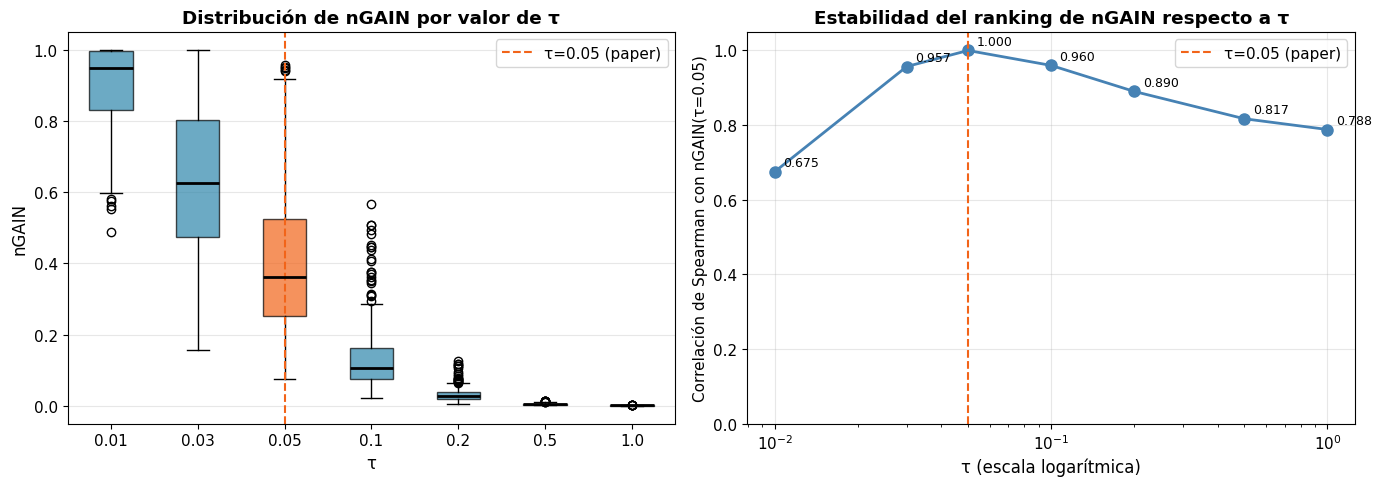

Figura guardada: fotos/ngain_sensitivity.png


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Panel izquierdo: boxplot por τ ---
ax1 = axes[0]
box_data   = [ngain_per_tau[tau] for tau in TAU_VALUES]
box_labels = [str(t) for t in TAU_VALUES]
bp = ax1.boxplot(box_data, labels=box_labels, patch_artist=True,
                 medianprops=dict(color='black', linewidth=2))
paper_idx = TAU_VALUES.index(TAU_PAPER) + 1  # 1-based
for i, patch in enumerate(bp['boxes']):
    patch.set_facecolor('#2E86AB' if (i + 1) != paper_idx else '#F26419')
    patch.set_alpha(0.7)
ax1.axvline(paper_idx, color='#F26419', linestyle='--', linewidth=1.5,
            label=f'τ={TAU_PAPER} (paper)')
ax1.set_xlabel('τ', fontsize=12)
ax1.set_ylabel('nGAIN', fontsize=12)
ax1.set_title('Distribución de nGAIN por valor de τ', fontweight='bold')
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# --- Panel derecho: correlación de Spearman vs τ=0.05 ---
ax2 = axes[1]
rhos = [spearmanr(ngain_ref, ngain_per_tau[t])[0] for t in TAU_VALUES]
ax2.plot(TAU_VALUES, rhos, 'o-', color='steelblue', linewidth=2, markersize=8)
ax2.axvline(TAU_PAPER, color='#F26419', linestyle='--', linewidth=1.5,
            label=f'τ={TAU_PAPER} (paper)')
for tau, r in zip(TAU_VALUES, rhos):
    ax2.annotate(f'{r:.3f}', (tau, r), textcoords='offset points',
                 xytext=(6, 4), fontsize=9)
ax2.set_xscale('log')
ax2.set_xlabel('τ (escala logarítmica)', fontsize=12)
ax2.set_ylabel('Correlación de Spearman con nGAIN(τ=0.05)', fontsize=11)
ax2.set_title('Estabilidad del ranking de nGAIN respecto a τ', fontweight='bold')
ax2.set_ylim(0, 1.05)
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FOTOS_DIR / 'ngain_sensitivity.png', dpi=300, bbox_inches='tight')
plt.show()
print('Figura guardada: fotos/ngain_sensitivity.png')

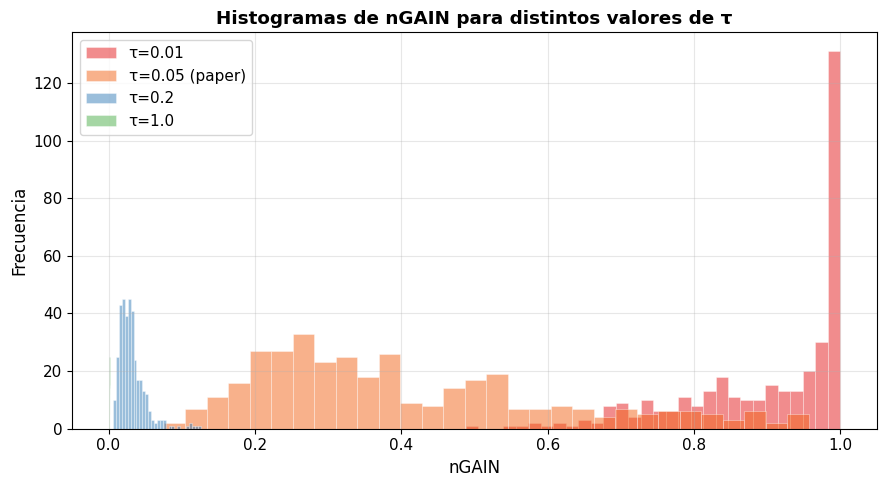

Figura guardada: fotos/ngain_sensitivity_hist.png


In [12]:
# Distribuciones superpuestas para τ extremos y el del paper
taus_plot = [0.01, 0.05, 0.2, 1.0]
colors_plot = ['#e41a1c', '#F26419', '#377eb8', '#4daf4a']

fig, ax = plt.subplots(figsize=(9, 5))
for tau, color in zip(taus_plot, colors_plot):
    label = f'τ={tau}' + (' (paper)' if tau == TAU_PAPER else '')
    ax.hist(ngain_per_tau[tau], bins=30, alpha=0.5, color=color, label=label,
            edgecolor='white', linewidth=0.5)
ax.set_xlabel('nGAIN', fontsize=12)
ax.set_ylabel('Frecuencia', fontsize=12)
ax.set_title('Histogramas de nGAIN para distintos valores de τ', fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FOTOS_DIR / 'ngain_sensitivity_hist.png', dpi=300, bbox_inches='tight')
plt.show()
print('Figura guardada: fotos/ngain_sensitivity_hist.png')